# Earthquake Magnitude and Depth Analysis

## Project Objective

This project analyzes earthquake records from the USGS Earthquake Catalog using Python.

The main objectives are to:
- Explore the distribution of earthquake magnitudes.
- Analyze earthquake depths.
- Compare magnitude distributions across depth groups.
- Investigate the correlation between earthquake depth and magnitude.

## Tools Used

- Python
- Pandas
- Matplotlib
- Google Colab

## Dataset

The analysis uses a saved snapshot of USGS earthquake records from September 10 to October 10, 2026, filtered to magnitude 2.5 or higher.

## 1. Load the Dataset

In [ ]:
import pandas as pd

# Load the saved USGS snapshot so the results are reproducible.
url = "https://raw.githubusercontent.com/mihirkanani8241-art/earthquake-magnitude-depth-analysis/main/earthquake_data.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.head())

(1896, 23)
                               time   latitude   longitude     depth   mag  \
0  2026-09-10 00:15:33.655000+00:00  31.640000 -104.408000    6.3306  3.00   
1  2026-09-10 01:24:04.400000+00:00  40.289333 -124.516333   20.3400  3.79   
2  2026-09-10 01:24:48.040000+00:00  40.290833 -124.531833   20.4400  3.63   
3  2026-09-10 01:57:36.656000+00:00 -21.004000  -69.222200  119.7040  4.30   
4  2026-09-10 02:22:11.219000+00:00  63.511000 -151.407000    5.0000  3.60   

  magType  nst  gap    dmin   rms  ...  \
0      ml   43   72  0.0000  0.20  ...   
1      mw   52  249  0.1329  0.18  ...   
2      mw   55  236  0.1448  0.18  ...   
3      mb   24   67  0.7030  0.91  ...   
4      ml  159   27  0.2000  1.40  ...   

                                       place        type horizontalError  \
0         59 km S of Whites City, New Mexico  earthquake        1.076538   
1                  20 km WSW of Petrolia, CA  earthquake        0.690000   
2                    21 km W of Petroli

## 2. Data Cleaning and Preprocessing

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1896 entries, 0 to 1895
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             1896 non-null   object 
 1   latitude         1896 non-null   float64
 2   longitude        1896 non-null   float64
 3   depth            1896 non-null   float64
 4   mag              1896 non-null   float64
 5   magType          1896 non-null   object 
 6   nst              1896 non-null   int64  
 7   gap              1896 non-null   int64  
 8   dmin             1895 non-null   float64
 9   rms              1896 non-null   float64
 10  net              1896 non-null   object 
 11  id               1896 non-null   object 
 12  updated          1896 non-null   object 
 13  place            1896 non-null   object 
 14  type             1896 non-null   object 
 15  horizontalError  1872 non-null   float64
 16  depthError       1890 non-null   float64
 17  magError      

In [ ]:
print(df.isna().sum())

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                 0
gap                 0
dmin                1
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError    24
depthError          6
magError           16
magNst              7
status              0
locationSource      0
magSource           0
date                0
dtype: int64


In [ ]:
df["time"]=pd.to_datetime(df["time"],format="mixed",utc=True)
print(df["time"].dtype)

datetime64[ns, UTC]


In [ ]:
df["date"]=df["time"].dt.date
print(df["date"])

0       2026-09-10
1       2026-09-10
2       2026-09-10
3       2026-09-10
4       2026-09-10
           ...    
1891    2026-10-10
1892    2026-10-10
1893    2026-10-10
1894    2026-10-10
1895    2026-10-10
Name: date, Length: 1896, dtype: object


## 3. Daily Earthquake Activity

In [ ]:
daily_counts = df["date"].value_counts().sort_index()

print(daily_counts)

date
2026-09-10    65
2026-09-11    78
2026-09-12    88
2026-09-13    65
2026-09-14    65
2026-09-15    74
2026-09-16    71
2026-09-17    62
2026-09-18    86
2026-09-19    60
2026-09-20    74
2026-09-21    69
2026-09-22    64
2026-09-23    69
2026-09-24    56
2026-09-25    56
2026-09-26    66
2026-09-27    75
2026-09-28    78
2026-09-29    57
2026-09-30    46
2026-10-01    44
2026-10-02    44
2026-10-03    42
2026-10-04    45
2026-10-05    44
2026-10-06    61
2026-10-07    41
2026-10-08    35
2026-10-09    64
2026-10-10    52
Name: count, dtype: int64


In [ ]:
largest=df.loc[df["mag"].idxmax()]
print("Magnitude:", largest["mag"])
print("Depth (km):", largest["depth"])
print("Location:", largest["place"])
print("Time:", largest["time"])

Magnitude: 7.7
Depth (km): 12.647
Location: 12 km WSW of Pitaloza Arriba, Panama
Time: 2026-10-09 17:56:06.036000+00:00


## 4. Magnitude Analysis

In [ ]:
print("Average magnitude:", df["mag"].mean())
print("Median magnitude:", df["mag"].median())
print("Average depth (km):", df["depth"].mean())
print("Shallowest depth (km):", df["depth"].min())
print("Deepest depth (km):", df["depth"].max())

Average magnitude: 3.776336565440346
Median magnitude: 4.0
Average depth (km): 56.23549551716057
Shallowest depth (km): -3.43
Deepest depth (km): 665.057


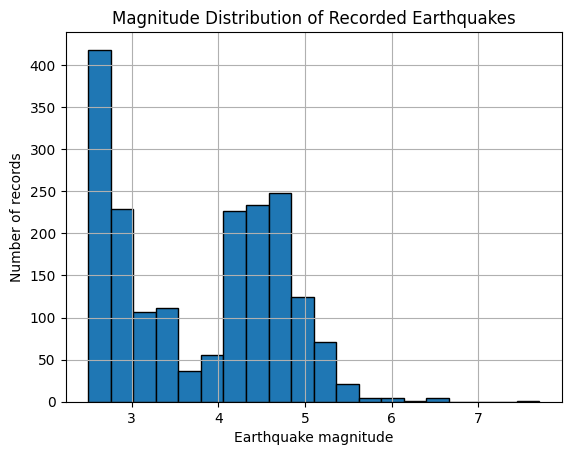

In [ ]:
import matplotlib.pyplot as plt
df["mag"].hist(bins=20,edgecolor="black")
plt.xlabel("Earthquake magnitude")
plt.ylabel("Number of records")
plt.title("Magnitude Distribution of Recorded Earthquakes")
plt.show()

In [ ]:
small=(df["mag"]<4).sum()
moderate=((df["mag"]>=4)&(df["mag"]<6)).sum()
large=(df["mag"]>=6).sum()
print("Small: ",small)
print("Moderate: ",moderate)
print("Large: ",large)

Small:  927
Moderate:  961
Large:  8


In [ ]:
print(small+moderate+large)
print(len(df))

1896
1896


In [ ]:
per=(large/len(df))*100
print(per)

0.42194092827004215


## 5. Depth Analysis


In [ ]:
deep=df[df["depth"]>300]
print("Earthquakes deeper than 300 km: ",len(deep))
print((deep[["mag","depth","place"]].head(10)))

Earthquakes deeper than 300 km:  67
     mag    depth                                    place
8    4.1  573.156                              Fiji region
18   4.3  451.154          179 km WNW of Manado, Indonesia
29   4.8  371.070                38 km S of Cliza, Bolivia
137  6.5  372.000       121 km NNE of Teluknaga, Indonesia
199  4.0  580.657                              Fiji region
201  4.3  301.453            Kermadec Islands, New Zealand
203  4.4  314.198     108 km NW of Arawa, Papua New Guinea
208  4.3  393.797  126 km WNW of Panguna, Papua New Guinea
225  4.3  368.234    93 km NNE of Rabaul, Papua New Guinea
231  4.1  363.296                23 km ENE of Owase, Japan


In [ ]:
shallow=df[df["depth"]<70]
deep=df[df["depth"]>300]

print("Shallow count:",len(shallow))
print("Shallow average magnitude: ",shallow["mag"].mean())
print("Deep count:",len(deep))
print("Deep average magnitude: ",deep["mag"].mean())

Shallow count: 1458
Shallow average magnitude:  3.720606397856581
Deep count: 67
Deep average magnitude:  4.410447761194032


## 6. Correlation Analysis

In [ ]:
correlation=df["depth"].corr(df["mag"])
print(correlation)

0.15207879791093068


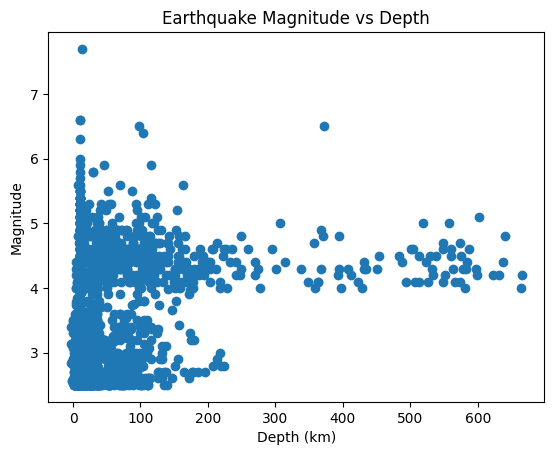

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["depth"],df["mag"])
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.title("Earthquake Magnitude vs Depth")
plt.show()

## 7. Comparing Earthquake Depth Groups

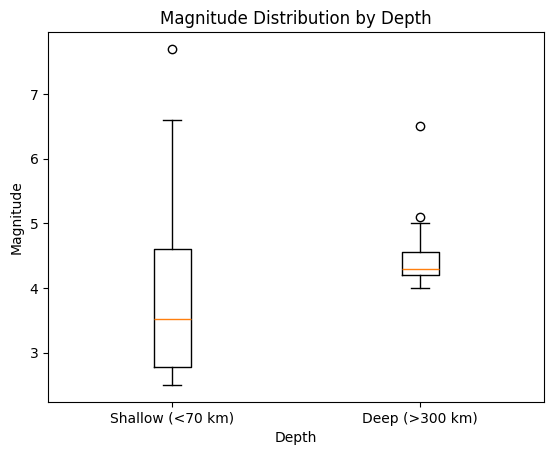

In [ ]:
plt.boxplot([shallow["mag"].dropna(), deep["mag"].dropna()],tick_labels=["Shallow (<70 km)","Deep (>300 km)"])
plt.xlabel("Depth")
plt.ylabel("Magnitude")
plt.title("Magnitude Distribution by Depth")
plt.show()

In [ ]:
shallow_median=shallow["mag"].median()
deep_median=deep["mag"].median()

print("Shallow median:", shallow_median)
print("Deep median:", deep_median)
print("Difference:", deep_median - shallow_median)

Shallow median: 3.525
Deep median: 4.3
Difference: 0.7749999999999999


In [ ]:
intermediate=df[(df["depth"]>=70)&(df["depth"]<=300)]
print("Intermediate count:",len(intermediate))
print("Intermediate median magnitude:",intermediate["mag"].median())

Intermediate count: 371
Intermediate median magnitude: 4.2


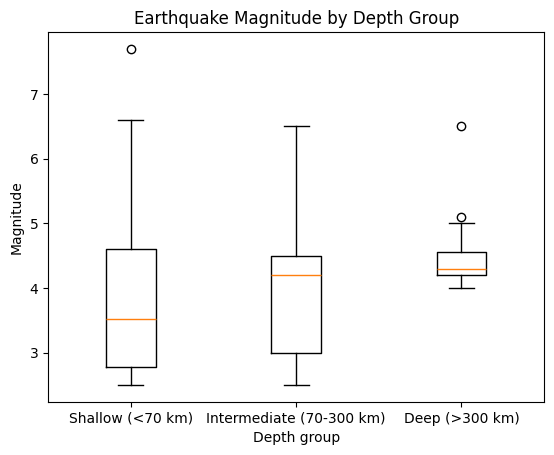

In [ ]:
plt.boxplot([shallow["mag"].dropna(), intermediate["mag"].dropna(), deep["mag"].dropna()],tick_labels=["Shallow (<70 km)","Intermediate (70-300 km)","Deep (>300 km)"])
plt.xlabel("Depth group")
plt.ylabel("Magnitude")
plt.title("Earthquake Magnitude by Depth Group")
plt.show()

In [ ]:
summary=pd.DataFrame({"Depth group": ["Shallow", "Intermediate", "Deep"],
                      "Count": [len(shallow),len(intermediate),len(deep)],
                      "Median magnitude": [shallow["mag"].median(), intermediate["mag"].median(), deep["mag"].median()]
                      })
print(summary)
summary.to_csv("earthquake_depth_summary.csv", index=False)

    Depth group  Count  Median magnitude
0       Shallow   1458             3.525
1  Intermediate    371             4.200
2          Deep     67             4.300


## 8. Key Findings and Conclusion

In [ ]:
print(summary)
print(summary.shape)

    Depth group  Count  Median magnitude
0       Shallow   1458             3.525
1  Intermediate    371             4.200
2          Deep     67             4.300
(3, 3)


### Key Findings

- The dataset contains 1,896 earthquake records with magnitudes of 2.5 or higher.
- The mean earthquake magnitude is approximately 3.78, and the median is 4.0.
- The Pearson correlation between depth and magnitude is approximately 0.152, indicating a weak positive linear association in this sample.
- The median magnitudes for shallow, intermediate, and deep earthquakes are 3.525, 4.2, and 4.3, respectively.

### Conclusion

This project used Python, Pandas, and Matplotlib to explore earthquake magnitude and depth data from the USGS catalog. The analysis found a weak positive association between depth and magnitude in the selected dataset. The depth-group comparison also showed differences in median magnitude. These observations describe this sample and do not establish causation or a universal pattern.

### Limitations

The dataset includes only earthquakes with magnitudes of 2.5 or higher. The depth groups have unequal sample sizes, and the results may be affected by geographic variation and measurement uncertainty.